In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

%matplotlib inline

sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
project_path = Path(
    r"C:\Users\suthi\Downloads\AI_Motor_Predictive_Maintenance"
)

results_path = project_path / "results"

csv_path = results_path / "complete_bearing_features.csv"

print("CSV path:", csv_path)

CSV path: C:\Users\suthi\Downloads\AI_Motor_Predictive_Maintenance\results\complete_bearing_features.csv


In [5]:
df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (3183, 14)


,Mean,RMS,Standard_Deviation,Variance,Minimum,Maximum,Peak_to_Peak,Kurtosis,Skewness,Crest_Factor,Label,Window_ID,Source_File,Signal_ID
0,0.012005,0.073256,0.072266,0.005222,-0.272869,0.217794,0.490663,-0.045824,-0.137322,3.724845,Normal,0,Normal_0.mat,X097_DE_time
1,0.013116,0.074507,0.073344,0.005379,-0.272869,0.212370,0.485239,-0.116338,-0.010099,3.662321,Normal,1,Normal_0.mat,X097_DE_time
2,0.012790,0.079035,0.077993,0.006083,-0.226765,0.223010,0.449775,-0.184580,-0.062348,2.869171,Normal,2,Normal_0.mat,X097_DE_time
3,0.012148,0.077916,0.076964,0.005923,-0.226765,0.223010,0.449775,-0.150657,-0.103819,2.910361,Normal,3,Normal_0.mat,X097_DE_time
4,0.011959,0.074338,0.073370,0.005383,-0.202148,0.219255,0.421403,-0.221760,0.025960,2.949440,Normal,4,Normal_0.mat,X097_DE_time


In [7]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3183 entries, 0 to 3182
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Mean                3183 non-null   float64
 1   RMS                 3183 non-null   float64
 2   Standard_Deviation  3183 non-null   float64
 3   Variance            3183 non-null   float64
 4   Minimum             3183 non-null   float64
 5   Maximum             3183 non-null   float64
 6   Peak_to_Peak        3183 non-null   float64
 7   Kurtosis            3183 non-null   float64
 8   Skewness            3183 non-null   float64
 9   Crest_Factor        3183 non-null   float64
 10  Label               3183 non-null   object 
 11  Window_ID           3183 non-null   int64  
 12  Source_File         3183 non-null   object 
 13  Signal_ID           3183 non-null   object 
dtypes: float64(10), int64(1), object(3)
memory usage: 348.3+ KB

Statistical Summary:


,Mean,RMS,Standard_Deviation,Variance,Minimum,Maximum,Peak_to_Peak,Kurtosis,Skewness,Crest_Factor,Window_ID
count,3183.000000,3183.000000,3183.000000,3183.000000,3183.000000,3183.000000,3183.000000,3183.000000,3183.000000,3183.000000,3183.000000
mean,0.013215,0.215954,0.214900,0.106684,-1.039899,1.091520,2.131419,2.664535,-0.098273,4.197560,167.733585
std,0.011260,0.245699,0.246010,0.196099,1.330024,1.418153,2.744565,6.764494,0.129081,1.765263,136.423991
min,0.002572,0.059770,0.058636,0.003438,-6.411721,0.157296,0.333785,-0.560307,-0.534779,2.609050,0.000000
25%,0.009146,0.065168,0.063961,0.004091,-1.611600,0.200479,0.402836,-0.152836,-0.186977,3.175890,56.000000
50%,0.011723,0.067942,0.066730,0.004453,-0.218629,0.222801,0.436215,-0.012874,-0.108699,3.443065,113.000000
75%,0.013912,0.310113,0.310010,0.096107,-0.197976,1.746015,3.361433,3.217364,-0.006466,4.699483,272.000000
max,0.093418,0.874031,0.874008,0.763890,-0.151246,6.652937,12.672783,41.286381,0.629254,12.482407,472.000000


In [9]:
# Section 3: Class distribution analysis
class_counts = df["Label"].value_counts()

print(class_counts)

Label
Normal        2124
Outer_Race    1059
Name: count, dtype: int64


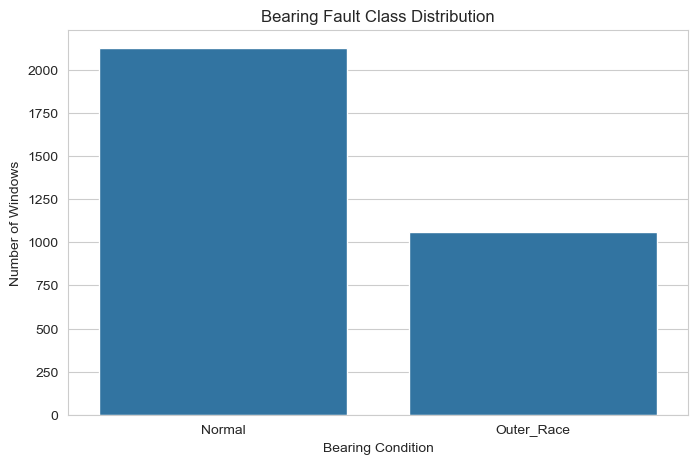

In [11]:
# Cell 6 – Visualize class distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Label"
)

plt.title("Bearing Fault Class Distribution")
plt.xlabel("Bearing Condition")
plt.ylabel("Number of Windows")

plt.show()

In [13]:
feature_columns = [
    "Mean",
    "RMS",
    "Standard_Deviation",
    "Variance",
    "Minimum",
    "Maximum",
    "Peak_to_Peak",
    "Kurtosis",
    "Skewness",
    "Crest_Factor"
]

class_comparison = df.groupby("Label")[feature_columns].mean()

display(class_comparison)

,Mean,RMS,Standard_Deviation,Variance,Minimum,Maximum,Peak_to_Peak,Kurtosis,Skewness,Crest_Factor
Label,,,,,,,,,,
Normal,0.012472,0.066589,0.065374,0.004285,-0.207035,0.209634,0.416669,-0.098832,-0.146639,3.296379
Outer_Race,0.014706,0.515529,0.514799,0.312061,-2.710345,2.860288,5.570633,8.206925,-0.001265,6.005028


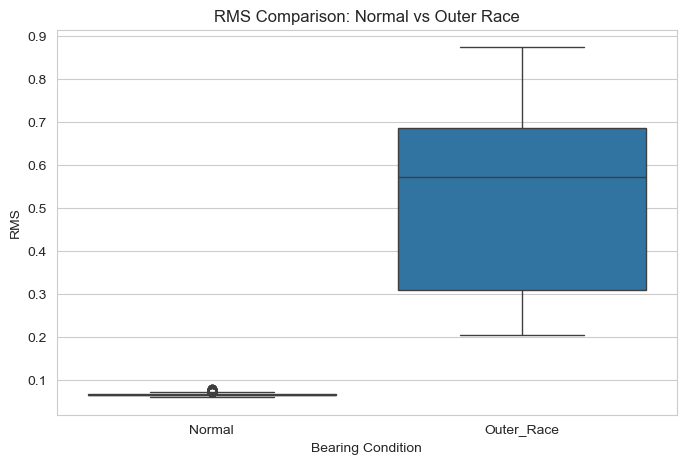

In [15]:
# Cell 8 – Compare RMS values
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Label",
    y="RMS"
)

plt.title("RMS Comparison: Normal vs Outer Race")
plt.xlabel("Bearing Condition")
plt.ylabel("RMS")

plt.show()

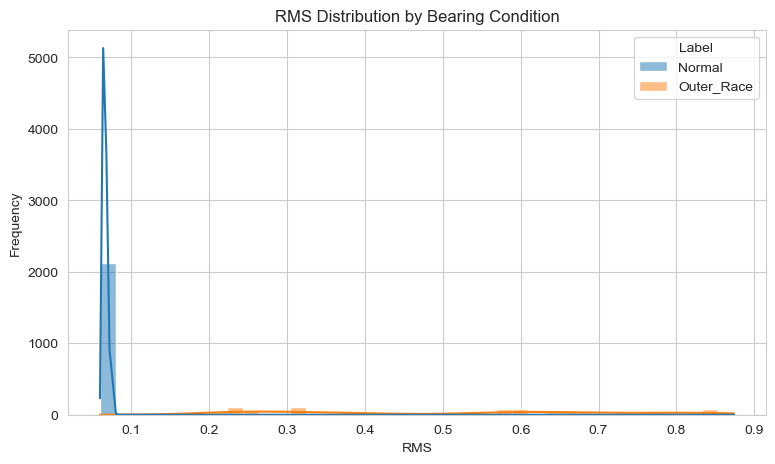

In [17]:
# Section 5: Feature distribution analysis
# Cell 9 – RMS distribution

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="RMS",
    hue="Label",
    kde=True,
    bins=40
)

plt.title("RMS Distribution by Bearing Condition")
plt.xlabel("RMS")
plt.ylabel("Frequency")

plt.show()

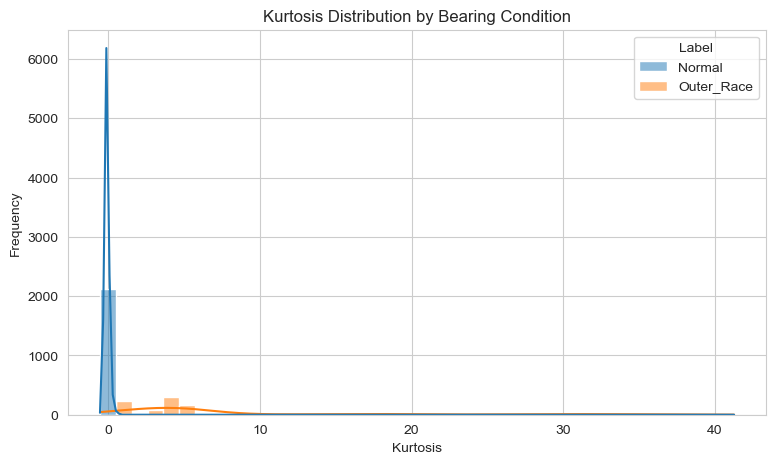

In [19]:
# Cell 10 – Kurtosis distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Kurtosis",
    hue="Label",
    kde=True,
    bins=40
)

plt.title("Kurtosis Distribution by Bearing Condition")
plt.xlabel("Kurtosis")
plt.ylabel("Frequency")

plt.show()

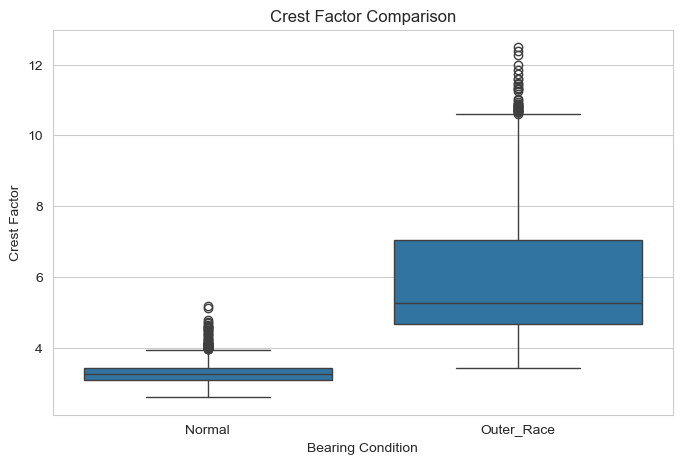

In [21]:
# Cell 11 – Crest Factor comparison
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Label",
    y="Crest_Factor"
)

plt.title("Crest Factor Comparison")
plt.xlabel("Bearing Condition")
plt.ylabel("Crest Factor")

plt.show()

In [23]:
# Section 6: Correlation analysis
correlation_matrix = df[feature_columns].corr()

display(correlation_matrix)

,Mean,RMS,Standard_Deviation,Variance,Minimum,Maximum,Peak_to_Peak,Kurtosis,Skewness,Crest_Factor
Mean,1.000000,0.001627,-0.002747,-0.069603,-0.217284,0.220257,0.219106,0.670640,-0.409497,0.473638
RMS,0.001627,1.000000,0.999989,0.974778,-0.898760,0.895630,0.898326,0.395700,0.588164,0.467953
Standard_Deviation,-0.002747,0.999989,1.000000,0.974970,-0.897870,0.894725,0.897426,0.392889,0.590077,0.466107
Variance,-0.069603,0.974778,0.974970,1.000000,-0.806045,0.803172,0.805621,0.248987,0.571292,0.296694
Minimum,-0.217284,-0.898760,-0.897870,-0.806045,1.000000,-0.994740,-0.998598,-0.723967,-0.462623,-0.774527
Maximum,0.220257,0.895630,0.894725,0.803172,-0.994740,1.000000,0.998767,0.723628,0.481948,0.780346
Peak_to_Peak,0.219106,0.898326,0.897426,0.805621,-0.998598,0.998767,1.000000,0.724745,0.473217,0.778553
Kurtosis,0.670640,0.395700,0.392889,0.248987,-0.723967,0.723628,0.724745,1.000000,-0.034393,0.931516
Skewness,-0.409497,0.588164,0.590077,0.571292,-0.462623,0.481948,0.473217,-0.034393,1.000000,0.154030
Crest_Factor,0.473638,0.467953,0.466107,0.296694,-0.774527,0.780346,0.778553,0.931516,0.154030,1.000000


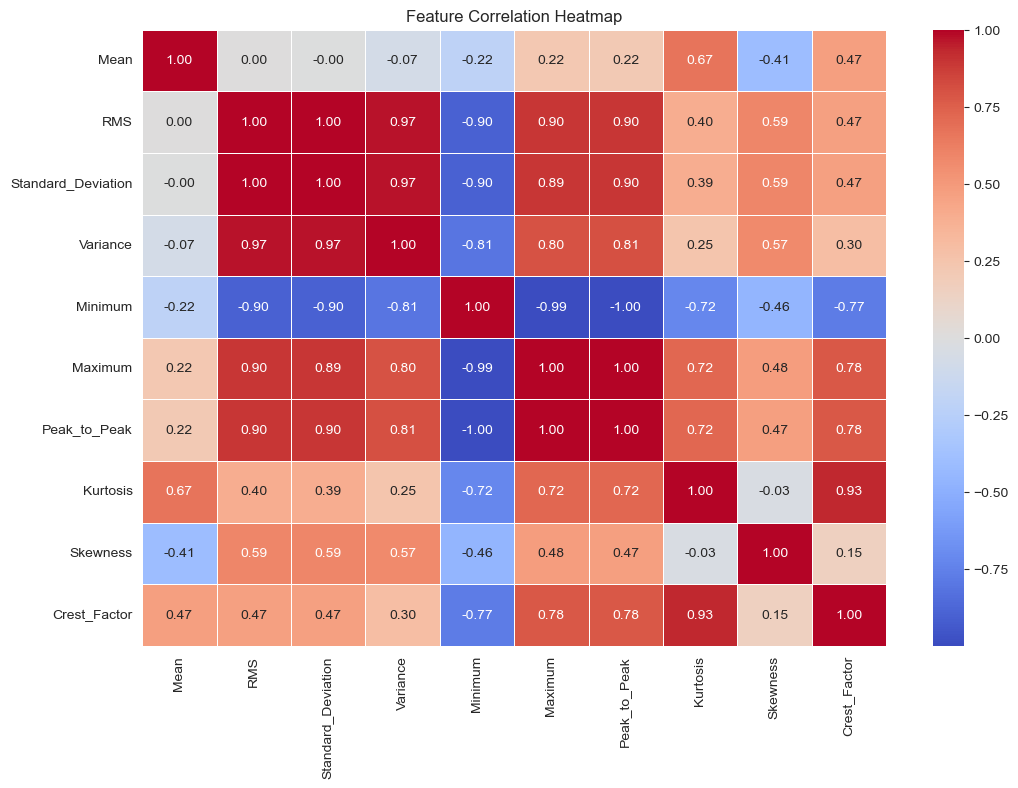

In [25]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")

plt.show()

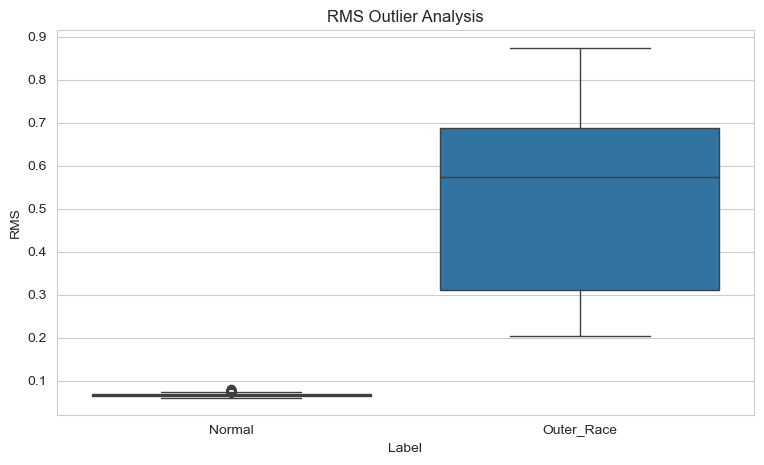

In [27]:
# Section 7: Outlier analysis
# Cell 14 – RMS outlier visualization

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Label",
    y="RMS"
)

plt.title("RMS Outlier Analysis")
plt.show()

In [29]:
for label in df["Label"].unique():

    class_data = df[df["Label"] == label]["RMS"]

    Q1 = class_data.quantile(0.25)
    Q3 = class_data.quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = class_data[
        (class_data < lower_limit) |
        (class_data > upper_limit)
    ]

    print("\nClass:", label)
    print("Total windows:", len(class_data))
    print("Outliers:", len(outliers))
    print("Outlier percentage:", round(
        len(outliers) / len(class_data) * 100, 2
    ), "%")


Class: Normal
Total windows: 2124
Outliers: 135
Outlier percentage: 6.36 %

Class: Outer_Race
Total windows: 1059
Outliers: 0
Outlier percentage: 0.0 %


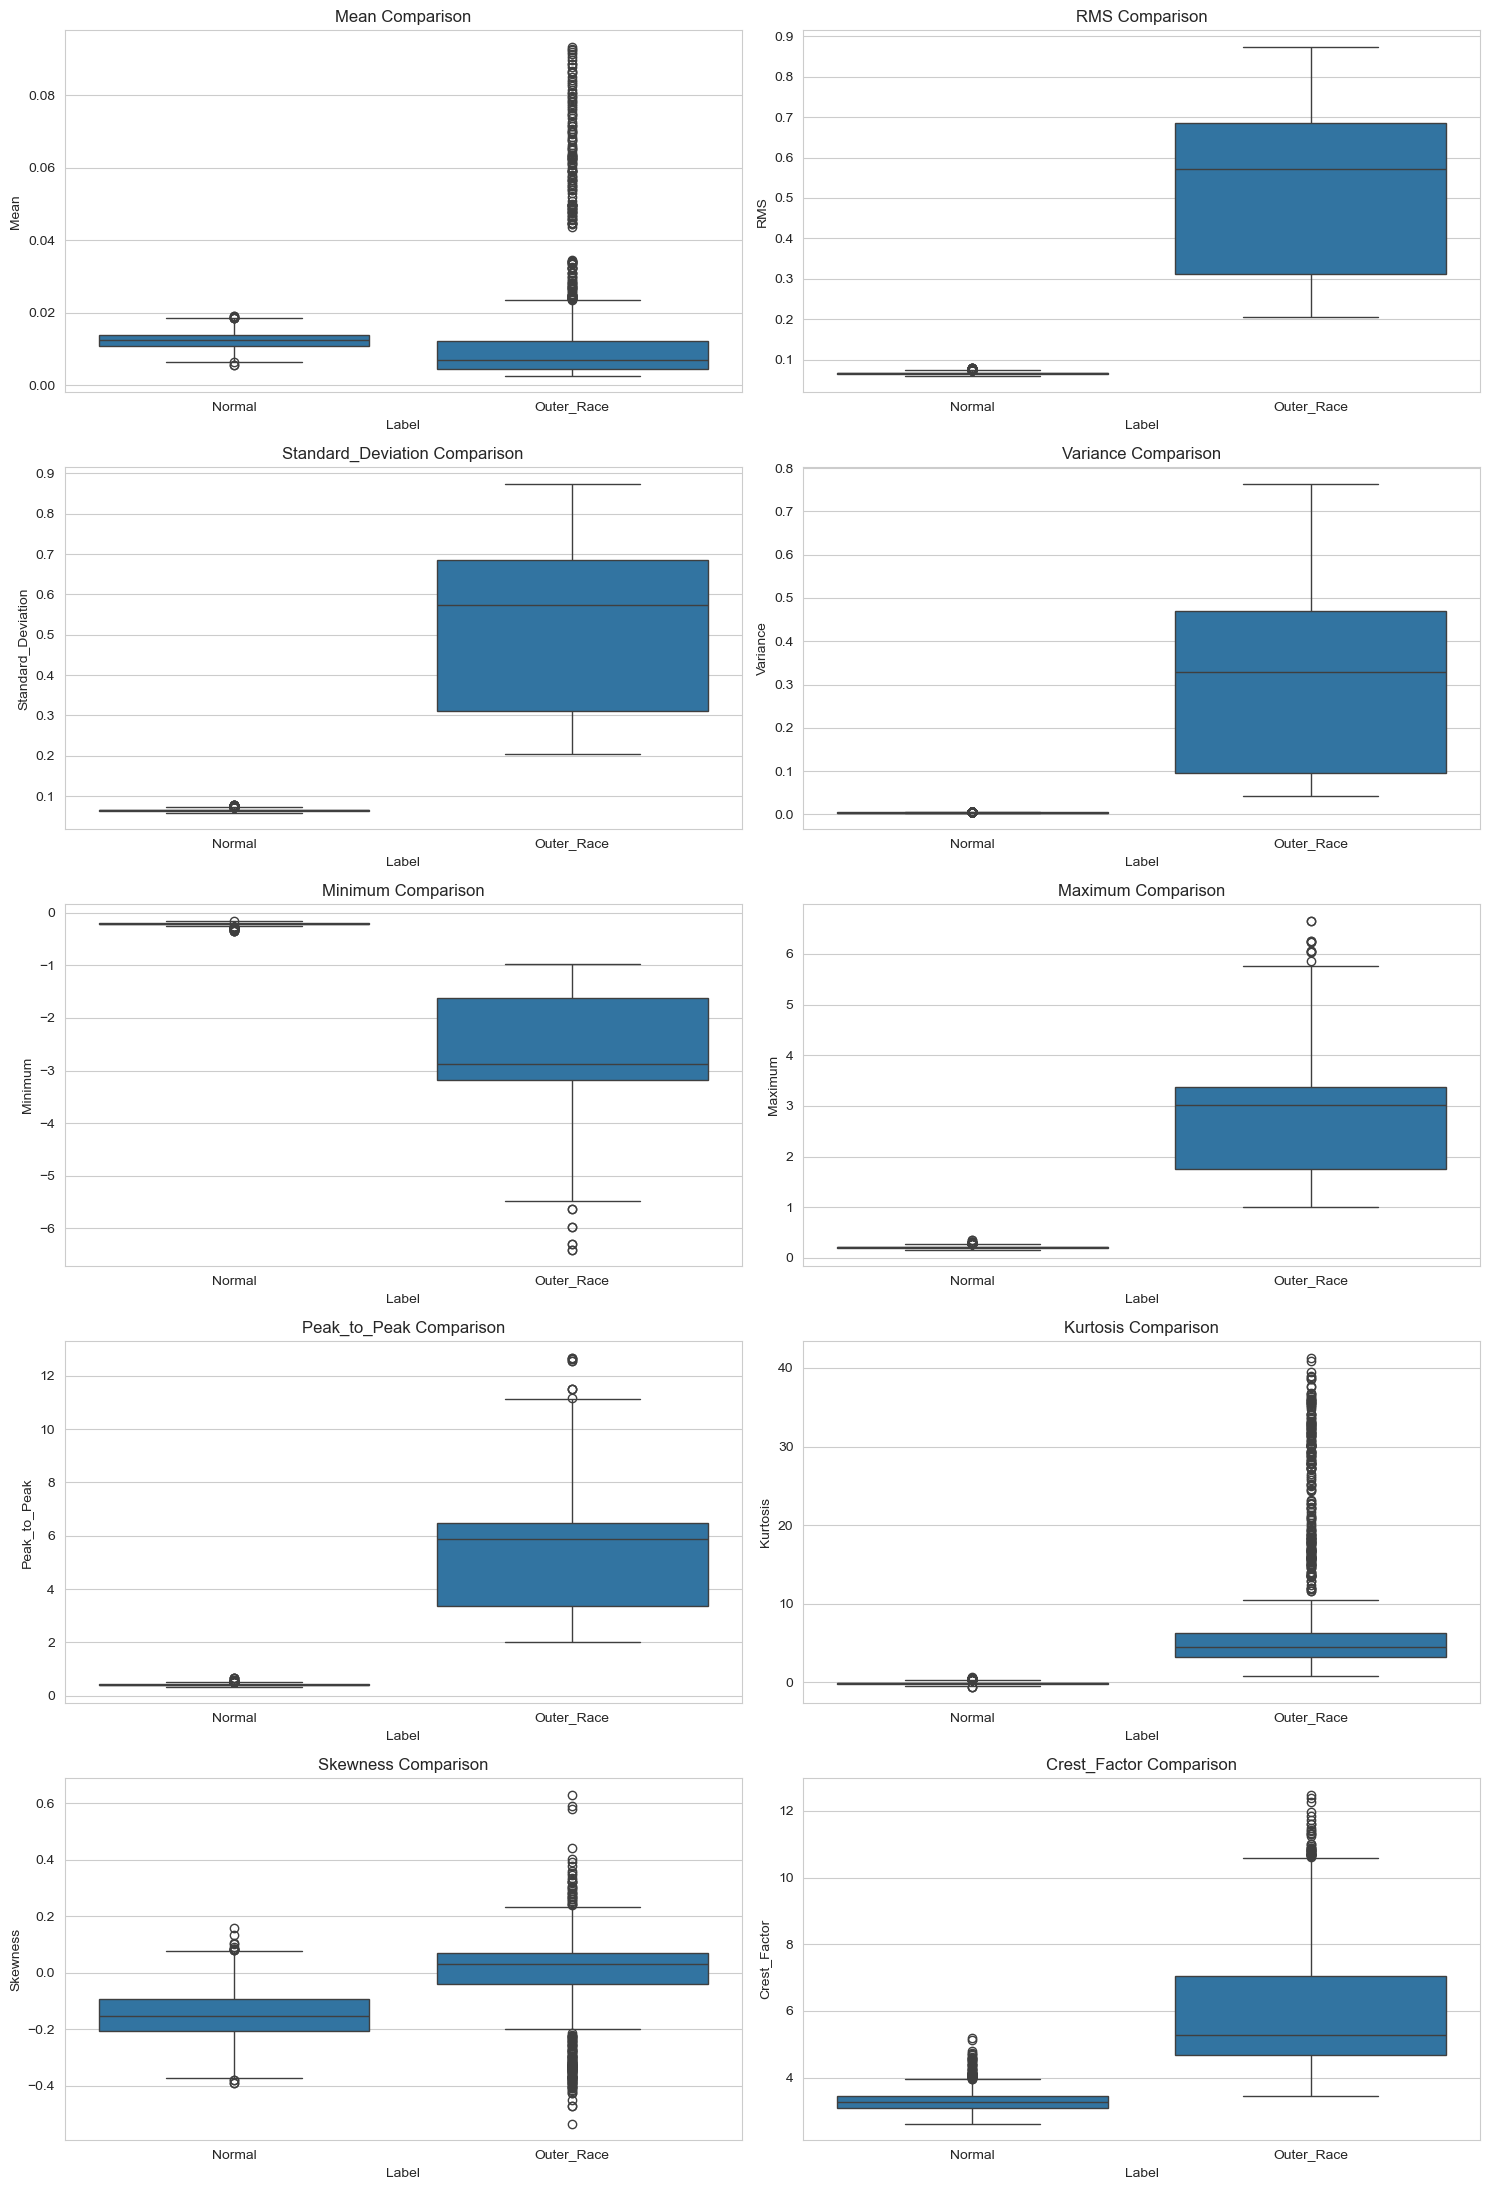

In [31]:
fig, axes = plt.subplots(5, 2, figsize=(15, 22))

for i, feature in enumerate(feature_columns):

    sns.boxplot(
        data=df,
        x="Label",
        y=feature,
        ax=axes[i // 2, i % 2]
    )

    axes[i // 2, i % 2].set_title(
        f"{feature} Comparison"
    )

plt.tight_layout()
plt.show()

In [33]:
normal_df = df[df["Label"] == "Normal"].copy()

Q1 = normal_df["RMS"].quantile(0.25)
Q3 = normal_df["RMS"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

normal_df["Is_Outlier"] = (
    (normal_df["RMS"] < lower_limit) |
    (normal_df["RMS"] > upper_limit)
)

outlier_summary = (
    normal_df.groupby("Source_File")["Is_Outlier"]
    .agg(["sum", "count"])
)

outlier_summary["Outlier_Percentage"] = (
    outlier_summary["sum"] /
    outlier_summary["count"] * 100
)

display(outlier_summary)

,sum,count,Outlier_Percentage
Source_File,,,
Normal_0.mat,131,237,55.274262
Normal_1.mat,2,471,0.424628
Normal_2.mat,2,943,0.212089
Normal_3.mat,0,473,0.000000


In [35]:
normal_rms_summary = (
    df[df["Label"] == "Normal"]
    .groupby("Source_File")["RMS"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
)

display(normal_rms_summary)

,count,mean,median,std,min,max
Source_File,,,,,,
Normal_0.mat,237,0.073733,0.073622,0.001981,0.068991,0.079491
Normal_1.mat,471,0.066312,0.066176,0.002380,0.060335,0.076710
Normal_2.mat,943,0.065305,0.065099,0.002323,0.059770,0.076710
Normal_3.mat,473,0.065844,0.065901,0.001988,0.060376,0.071311


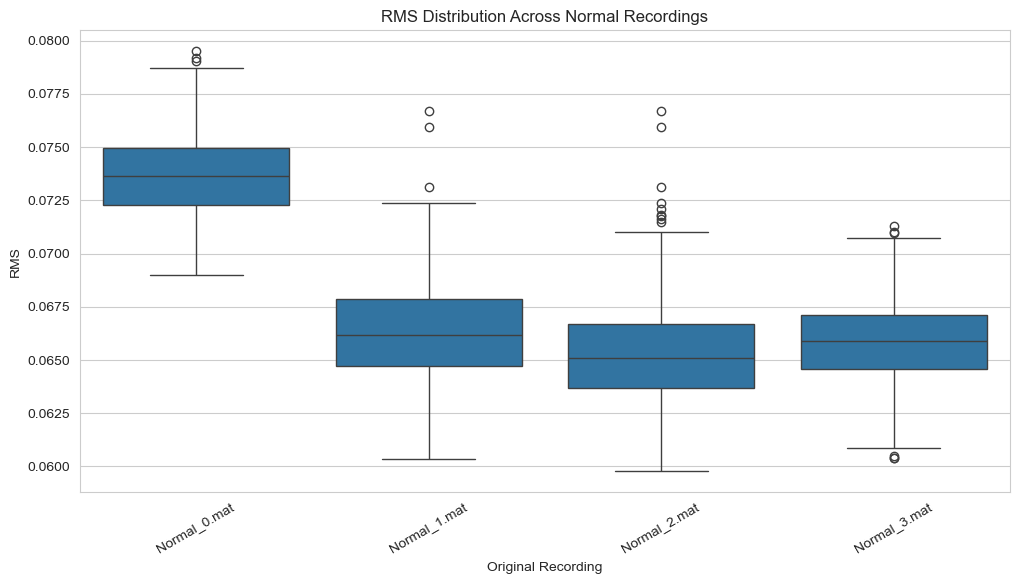

In [37]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df[df["Label"] == "Normal"],
    x="Source_File",
    y="RMS"
)

plt.title("RMS Distribution Across Normal Recordings")
plt.xlabel("Original Recording")
plt.ylabel("RMS")
plt.xticks(rotation=30)

plt.show()

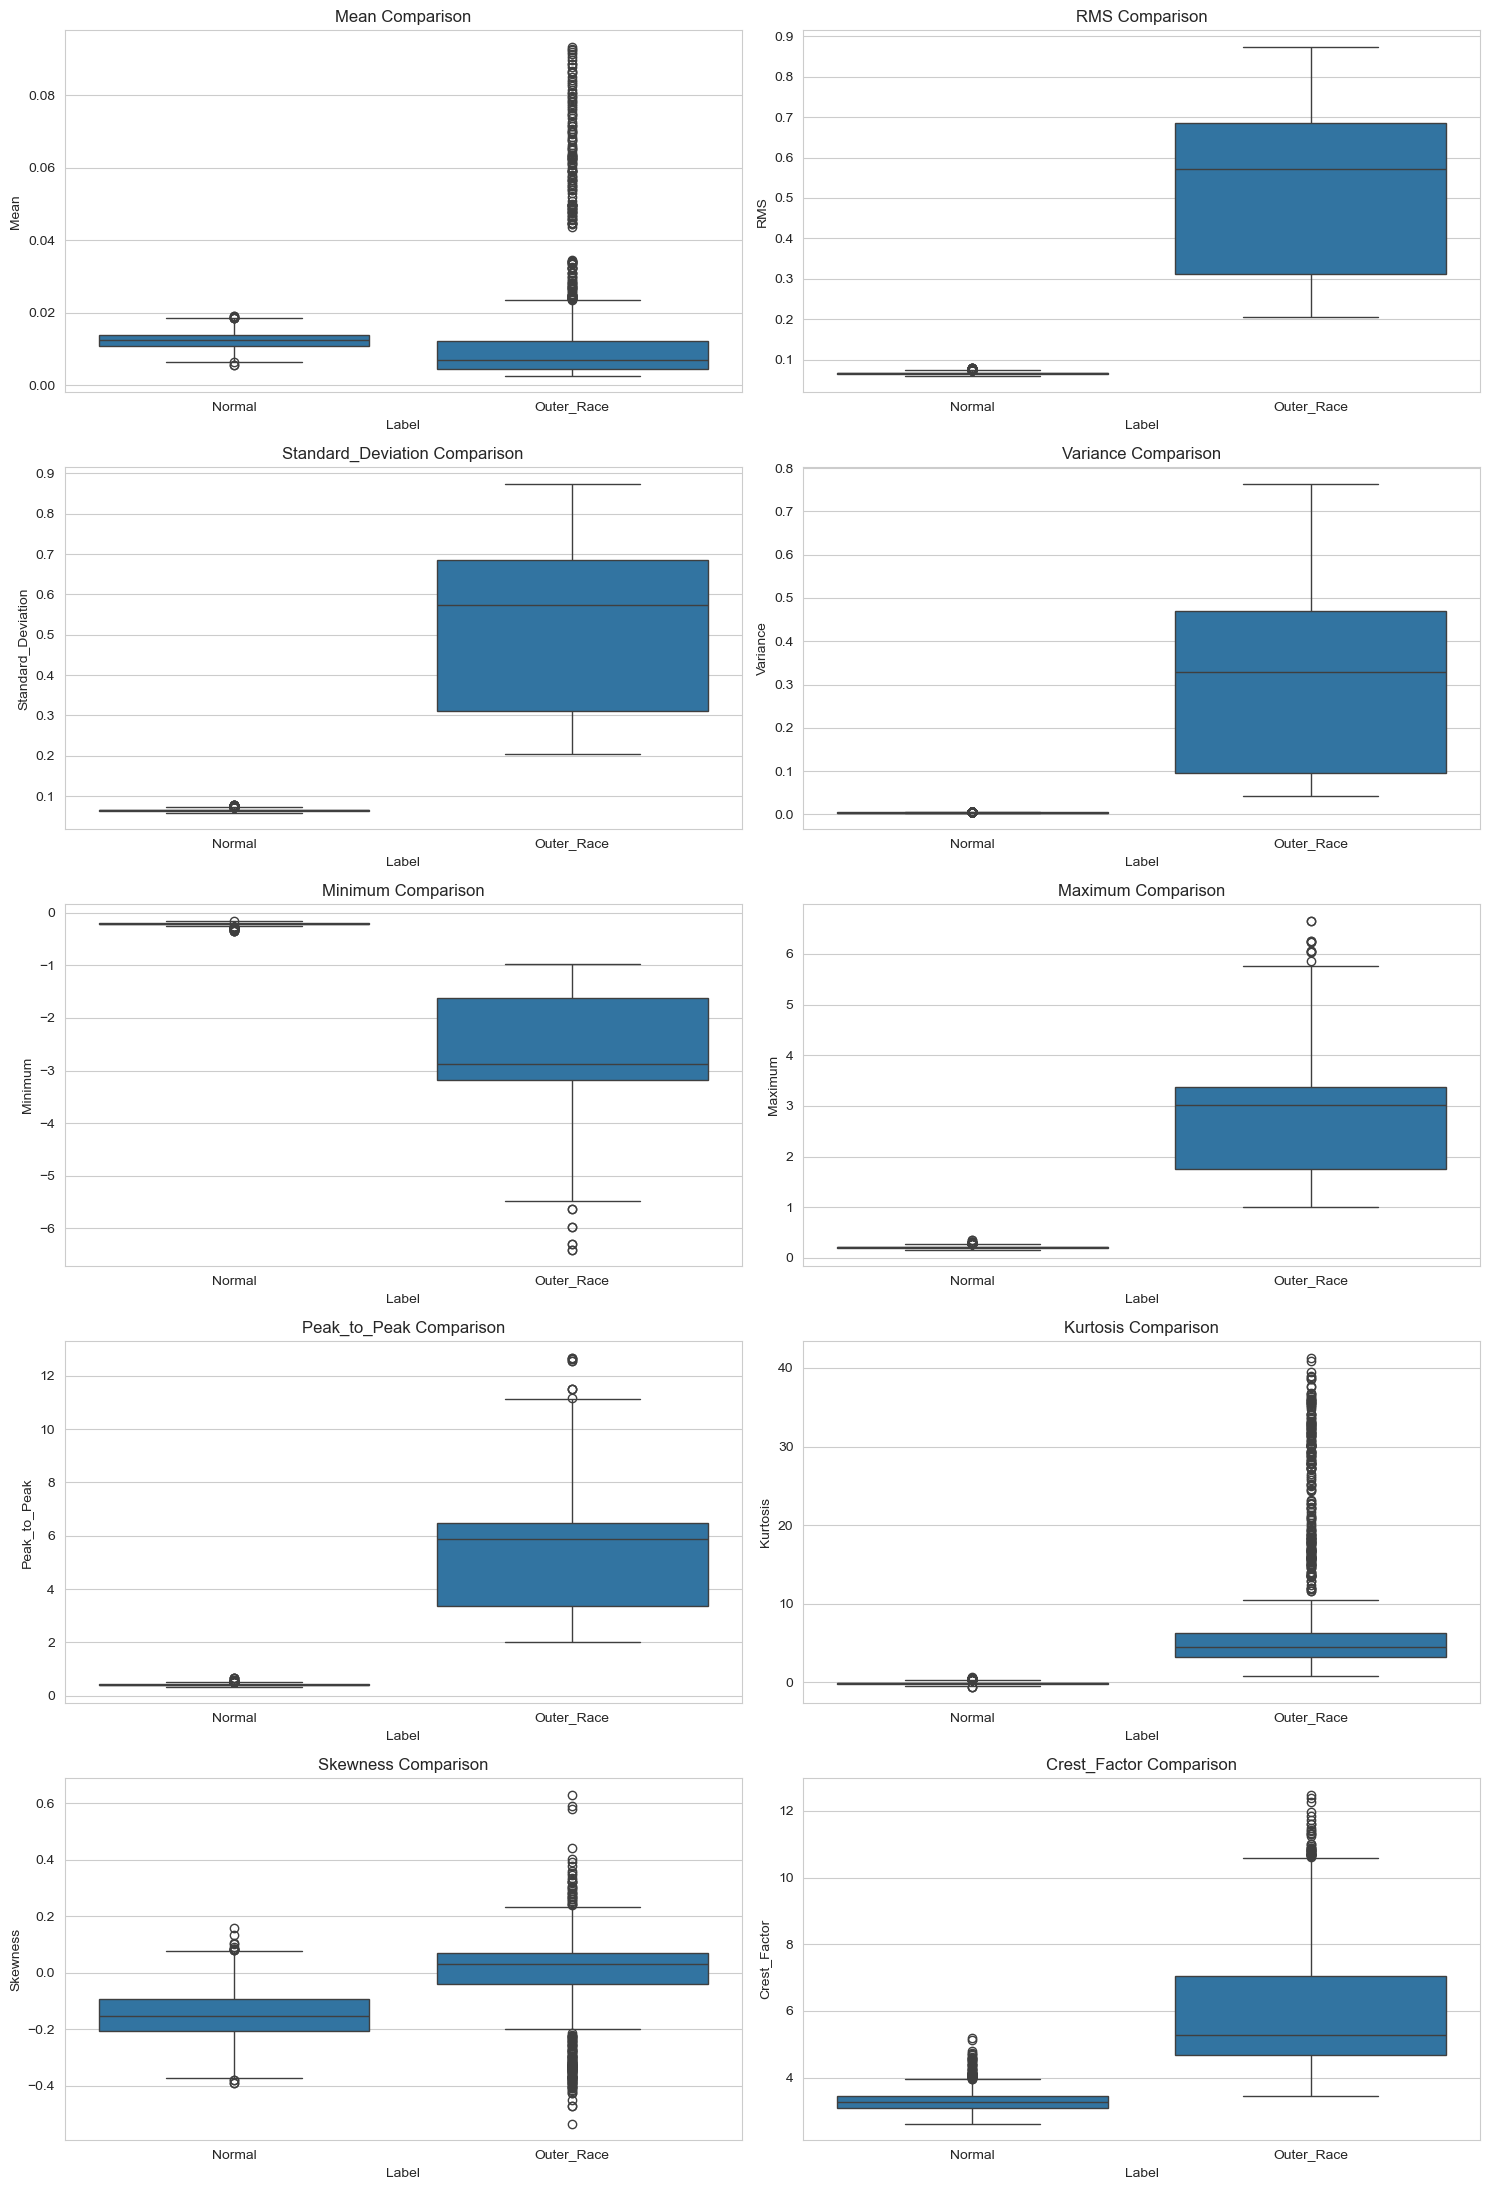

In [39]:
fig, axes = plt.subplots(5, 2, figsize=(15, 22))

for i, feature in enumerate(feature_columns):

    sns.boxplot(
        data=df,
        x="Label",
        y=feature,
        ax=axes[i // 2, i % 2]
    )

    axes[i // 2, i % 2].set_title(
        f"{feature} Comparison"
    )

plt.tight_layout()
plt.show()

# Final Conclusion – Exploratory Data Analysis

Exploratory Data Analysis was performed on 3,183 vibration windows containing Normal and Outer Race bearing conditions.

The analysis revealed significant differences between the two classes.

The Outer Race class showed substantially higher RMS, standard deviation, variance, peak-to-peak amplitude, kurtosis and crest factor.

Boxplot visualizations demonstrated strong separation between Normal and Outer Race distributions for several vibration features.

RMS, Kurtosis, Peak-to-Peak, Variance and Crest Factor appear particularly promising for machine-learning classification.

Outlier analysis identified recording-level differences within the Normal class. All observations were retained for further investigation.

The findings indicate that statistical features extracted from vibration signals can potentially be used to develop an AI-based bearing fault classification system.

Further validation using recording-independent training and testing is required to establish model reliability.